**1)A retail store wants to identify customers who make frequent purchases. Given the dataset below, write a code to:**

In [1]:
import pandas as pd

In [2]:
data = {'Customer_ID': [101, 102, 103, 101, 104, 102, 101, 105, 102, 103],
        'Purchase_Amount': [200, 150, 180, 220, 300, 200, 100, 400, 250, 300]}

In [3]:
df = pd.DataFrame(data)

**Group Customers by their IDs**

In [8]:
grouped = df.groupby('Customer_ID')['Purchase_Amount'].sum()
grouped

Customer_ID
101    520
102    600
103    480
104    300
105    400
Name: Purchase_Amount, dtype: int64

**Calculate the total number of purchases per customer**

In [11]:
calculate = df.groupby('Customer_ID')['Purchase_Amount'].sum().nlargest(3)
calculate

Customer_ID
102    600
101    520
103    480
Name: Purchase_Amount, dtype: int64

**2)A company tracks the daily sales of a product over a month. 
You are tasked with identifying any abnormal sales data using the IQR (Interquartile Range) method.**

In [13]:
data1 = {'Day': range(1, 31),
        'Sales': [25, 30, 28, 45, 55, 60, 22, 80, 95, 120,
                  33, 29, 27, 35, 40, 50, 85, 110, 105, 92,
                  30, 34, 31, 33, 36, 42, 44, 48, 90, 200]}

In [30]:
df1 = pd.DataFrame(data1)
df1

,Day,Sales
0,1,25
1,2,30
2,3,28
3,4,45
4,5,55
5,6,60
6,7,22
7,8,80
8,9,95
9,10,120


**Calculate the Q1 (25th percentile) and Q3 (75th percentile).**

In [21]:
Q1 = df1.describe()['Sales']["25%"]
print("Q1",Q1)
Q3 = df1.describe()['Sales']["75%"]
print("Q3",Q3)
IQR = Q3 - Q1
print("IQR",IQR)

Q1 31.5
Q3 83.75
IQR 52.25


**Calculate Lower and Upper Bound**

In [23]:
rule = 1.5 * IQR
Lower_Bound = Q1 - rule
print("Lower_Bound", Lower_Bound)
Upper_Bound = Q3 + rule
print("Upper_Bound", Upper_Bound)

Lower_Bound -46.875
Upper_Bound 162.125


**Find the outlier**

In [26]:
def outlier_column(Sales):
      lesser = []
      greater = []
      for columnName in Sales:
          if columnName < Lower_Bound:
             lesser.append(columnName)
    
          if columnName > Upper_Bound:
            greater.append(columnName)           
      return lesser, greater


In [28]:
lesser, greater = outlier_column(df1['Sales'])

In [29]:
print(lesser)
print(greater)

[]
[200]


**Replace the outlier with median**

In [44]:
def replacement_outlier(df1, greater):
    median_value = df1['Sales'].median()
    for value in greater:
        df1.loc[df1['Sales'] == value, 'Sales'] = median_value
    return df1

In [45]:
df1 = replacement_outlier(df1, greater)

In [46]:
df1

,Day,Sales
0,1,25.0
1,2,30.0
2,3,28.0
3,4,45.0
4,5,55.0
5,6,60.0
6,7,22.0
7,8,80.0
8,9,95.0
9,10,120.0


**3) A pharmaceutical company is testing the effectiveness of a new drug to reduce blood pressure. Two groups of patients were selected:
Group 1 (Treatment): Received the drug
Group 2 (Control): Received a placebo**

In [49]:
data2 = {'Group': ['Treatment']*10 + ['Control']*10,
        'Blood_Pressure': [120, 115, 118, 123, 122, 119, 124, 117, 116, 121,
                            130, 135, 140, 138, 142, 136, 139, 134, 137, 141]}

In [51]:
dataset = pd.DataFrame(data2)
dataset

,Group,Blood_Pressure
0,Treatment,120
1,Treatment,115
2,Treatment,118
3,Treatment,123
4,Treatment,122
5,Treatment,119
6,Treatment,124
7,Treatment,117
8,Treatment,116
9,Treatment,121


**Perform an Independent T-Test, Calculate P value**

In [52]:
from scipy.stats import ttest_ind
dataset = dataset.dropna()
treatment = dataset[dataset['Group'] == 'Treatment']['Blood_Pressure']
control = dataset[dataset['Group'] == 'Control']['Blood_Pressure']
ttest_ind(treatment,control)

TtestResult(statistic=np.float64(-11.870553692962726), pvalue=np.float64(6.008066605173383e-10), df=np.float64(18.0))

P-Value is greater than 0.05
Solution : Reject Null hypothesis so Accept alternate hypothesis

**4)GlobalMart is a large retailer conducting advertisement campaigns in different regions. 
The company spends money on two types of advertisements: TV Ads and Social Media Ads**

In [53]:
data3 = {
    'Region': ['North', 'South', 'East', 'West', 'Central'],
    'TV_Ad_Budget': [200, 300, 400, 500, 600],
    'Social_Media_Budget': [150, 250, 300, 450, 500],
    'Sales': [20, 35, 50, 60, 80]
}

df3 = pd.DataFrame(data3)

In [54]:
df3

,Region,TV_Ad_Budget,Social_Media_Budget,Sales
0,North,200,150,20
1,South,300,250,35
2,East,400,300,50
3,West,500,450,60
4,Central,600,500,80


**Calculate the Covariance**

In [57]:
def quanqual(df3):
        qual = []
        quan = []
        for columnName in df3.columns:
            if(df3[columnName].dtype.name == "str"):
               qual.append(columnName) 
            else:
               quan.append(columnName)
        return quan,qual  

In [58]:
quan,qual = quanqual(df3)

In [59]:
df3[quan].cov()

,TV_Ad_Budget,Social_Media_Budget,Sales
TV_Ad_Budget,25000.0,22500.0,3625.0
Social_Media_Budget,22500.0,20750.0,3225.0
Sales,3625.0,3225.0,530.0


Covariance(TV vs Sales): 3625.0
Covariance(Social Media vs Sales): 3225.0

**Calculate the correlation**

In [60]:
df3[quan].corr()

,TV_Ad_Budget,Social_Media_Budget,Sales
TV_Ad_Budget,1.000000,0.987878,0.995864
Social_Media_Budget,0.987878,1.000000,0.972485
Sales,0.995864,0.972485,1.000000


Correlation (TV vs Sales): 0.995864
Correlation (Social Media vs Sales): 0.972485
TV Ads have a stronger impact on sales(0.995864)

**5)A company tracks the delivery time (in minutes) for its online orders. 
You are given the delivery times for 50 orders.**

In [63]:
data4 = [25, 30, 28, 45, 55, 60, 22, 80, 95, 120, 33, 29, 27, 35, 40, 50, 85, 110, 105, 92, 30, 34, 31, 33, 36, 42, 44, 48, 90, 200, 20, 25, 27, 32, 38, 41, 47, 58, 62, 77, 80, 84, 90, 110, 123, 145, 150, 160]

In [65]:
dataset = pd.DataFrame(data4)

In [78]:
def get_pdf_probability(dataset):

    from matplotlib import pyplot
    from scipy.stats import norm
    import seaborn as sns

    sample = dataset.dropna()

    sns.histplot(sample, kde=True, color='green')

    sample_mean = sample.mean()
    sample_std = sample.std()

    print('Mean=%.3f, Standard Deviation=%.3f' %
          (sample_mean, sample_std))

    dist = norm(sample_mean, sample_std)

    prob = dist.cdf(sample.max()) - dist.cdf(sample.min())

    print("Total probability:", prob)

    return prob

**Mean and Standard Deviation, Calculate PDF**

Mean=65.062, Standard Deviation=42.160
Total probability: 0.8567446207855534


np.float64(0.8567446207855534)

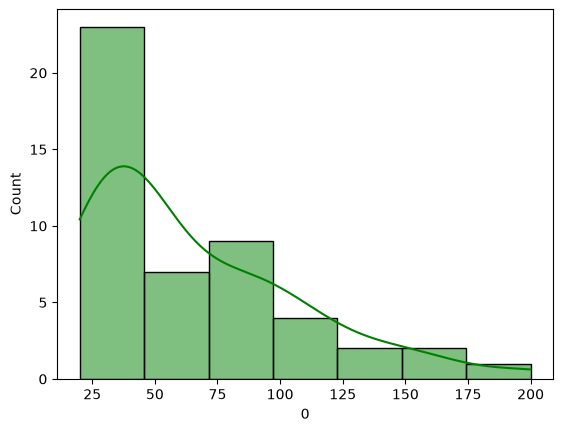

In [79]:
get_pdf_probability(dataset[0])